# Filtros espaciales pasaaltos y detección de bordes

**Procesamiento de Imágenes — Universidad Diego Portales**

En el cuaderno anterior los kernels tenían coeficientes positivos que sumaban 1
y el efecto era suavizar. Ahora los coeficientes tienen **signos distintos**, y
el efecto es el opuesto: destacar las transiciones y anular las zonas planas.

## 1. Preparación

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

print("OpenCV:", cv2.__version__)

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["image.cmap"] = "gray"

# Imágenes de trabajo (skimage entrega RGB; OpenCV trabaja en BGR)
img = data.camera()                       # 512x512, uint8, ya en grises
monedas = data.coins()                    # bordes circulares, buen caso de umbral
tablero = data.checkerboard()             # bordes horizontales y verticales puros
ladrillos = data.brick()                  # textura regular, útil para la escala
color = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)

for nombre, im in [("camera", img), ("coins", monedas),
                   ("checkerboard", tablero), ("brick", ladrillos),
                   ("astronaut", color)]:
    print(f"{nombre:14s} {str(im.shape):16s} {im.dtype}")

OpenCV: 5.0.0
camera         (512, 512)       uint8
coins          (303, 384)       uint8
checkerboard   (200, 200)       uint8
brick          (512, 512)       uint8
astronaut      (512, 512, 3)    uint8


In [2]:
def mostrar(imagenes, titulos=None, cols=None, escala=3.4, cmap="gray"):
    """Muestra imágenes uint8 (gris o BGR) en una grilla."""
    if isinstance(imagenes, np.ndarray):
        imagenes = [imagenes]
    if titulos is None:
        titulos = [""] * len(imagenes)
    if isinstance(titulos, str):
        titulos = [titulos]

    n = len(imagenes)
    cols = cols or n
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols,
                            figsize=(escala * cols, escala * filas * 1.05))
    axs = np.atleast_1d(axs).ravel()

    for ax, im, t in zip(axs, imagenes, titulos):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap=cmap, vmin=0, vmax=255)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    for ax in axs[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def mostrar_signo(mapas, titulos=None, cols=None, escala=3.4):
    """Muestra mapas CON SIGNO (float) con un colormap divergente
    centrado en cero: azul = negativo, rojo = positivo, blanco = 0."""
    if isinstance(mapas, np.ndarray):
        mapas = [mapas]
    if titulos is None:
        titulos = [""] * len(mapas)
    if isinstance(titulos, str):
        titulos = [titulos]

    n = len(mapas)
    cols = cols or n
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols,
                            figsize=(escala * cols, escala * filas * 1.05))
    axs = np.atleast_1d(axs).ravel()

    for ax, m, t in zip(axs, mapas, titulos):
        lim = np.abs(m).max()
        im = ax.imshow(m, cmap="coolwarm", vmin=-lim, vmax=lim)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046)
    for ax in axs[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 2. El puente: qué dice la suma de los coeficientes

Toda la diferencia entre las tres familias de filtros lineales está en un solo
número: $\sum_{i,j} h(i,j)$.

| Suma | Coeficientes | Efecto | Ejemplo |
|---|---|---|---|
| **1** | todos positivos | suaviza, conserva el brillo medio | promedio, gaussiano |
| **0** | con signo | anula lo constante, deja solo transiciones | Sobel, Prewitt |
| **1** | con signo | conserva el brillo y realza | *unsharp masking* |

La clave del caso "suma 0": sobre una región de intensidad constante $c$, la
salida es $c \sum h(i,j) = 0$. El filtro **no responde a lo que no cambia**. Por
eso el fondo de un mapa de bordes es negro: no es que el filtro "pinte" los
bordes, es que anula todo lo demás.

### Todo pasaaltos es un original menos su versión suavizada

Si $h_{\text{bajo}}$ es un kernel pasabajos y $\delta$ es el impulso unitario
(un 1 en el centro y ceros alrededor), entonces

$$h_{\text{alto}} = \delta - h_{\text{bajo}}$$

tiene suma $1 - 1 = 0$. Aplicarlo equivale a restarle a la imagen su versión
suavizada: lo que queda es el **detalle**, es decir, lo que el pasabajos
eliminó. Descomposición: `imagen = aproximación + detalle`.

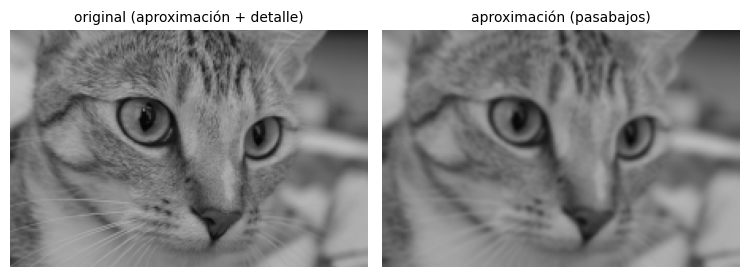

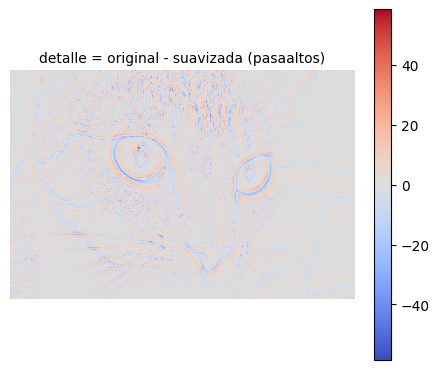

Rango del detalle: -42.5 a 58.6
Media del detalle: 0.003   <- cercana a 0


In [3]:
img = data.chelsea()
img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
# resize a la mitad para acelerar el filtrado
img = cv2.resize(img, (0, 0), fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

gaussian_kernel = cv2.getGaussianKernel(ksize=11, sigma=1)
gaussian_kernel = gaussian_kernel @ gaussian_kernel.T

suavizada = cv2.filter2D(img, cv2.CV_64F, gaussian_kernel)
detalle = img.astype(np.float64) - suavizada

mostrar([img, suavizada.astype(np.uint8)],
        ["original (aproximación + detalle)", "aproximación (pasabajos)"],
        escala=3.8)
mostrar_signo(detalle, "detalle = original - suavizada (pasaaltos)", escala=4.5)

print("Rango del detalle:", detalle.min().round(1), "a", detalle.max().round(1))
print("Media del detalle:", detalle.mean().round(3), "  <- cercana a 0")

## 3. La trampa de los tipos de datos

Este es el error número uno al pasar de pasabajos a pasaaltos, y conviene verlo
**antes** de mirar cualquier resultado.

Con un kernel de suma 0 la salida tiene valores negativos y puede superar 255.
Si se usa `ddepth=-1`, la salida se guarda en `uint8`: los negativos se
truncan a 0 y lo que excede se satura en 255. Se pierde información sin ningún
mensaje de error.

In [4]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], np.float32)

img = data.checkerboard()
#img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
g_uint8 = cv2.filter2D(img, -1, sobel_x)            # MAL: ddepth=-1
g_float = cv2.filter2D(img, cv2.CV_64F, sobel_x)    # BIEN: float con signo

print("Rango real de la respuesta:", g_float.min(), "a", g_float.max())
print("Píxeles negativos (se truncan a 0)  : %.1f%%" % (100 * (g_float < 0).mean()))
print("Píxeles sobre 255 (se saturan)      : %.1f%%" % (100 * (g_float > 255).mean()))

Rango real de la respuesta: -820.0 a 820.0
Píxeles negativos (se truncan a 0)  : 7.5%
Píxeles sobre 255 (se saturan)      : 3.5%


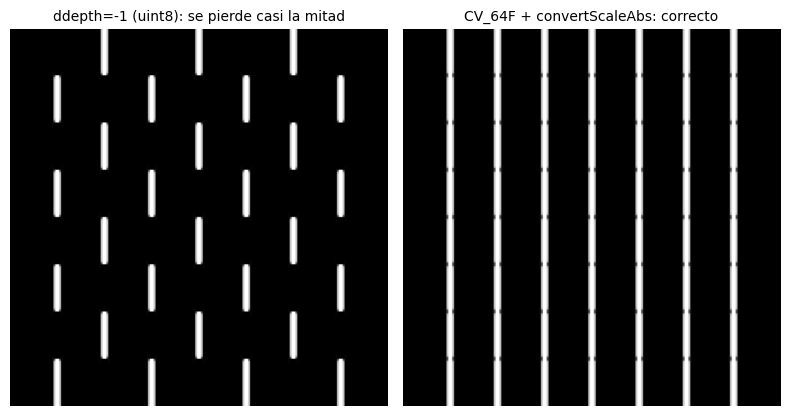

In [5]:
mostrar([g_uint8, cv2.convertScaleAbs(g_float)],
        ["ddepth=-1 (uint8): se pierde casi la mitad",
         "CV_64F + convertScaleAbs: correcto"],
        escala=4.0)

### Tres formas de visualizar un mapa con signo

Cada una responde una pregunta distinta, y elegir mal la visualización lleva a
conclusiones equivocadas:

- **Valor absoluto** (`convertScaleAbs`): "¿dónde hay cambio?". Pierde el
  sentido de la transición.
- **Normalización** a 0–255 (`normalize` con `NORM_MINMAX`): el gris medio pasa
  a representar el cero. Conserva el signo pero cuesta leerlo.
- **Colormap divergente** centrado en cero: el más claro para analizar, aunque
  no sirva para encadenar con otro procesamiento.

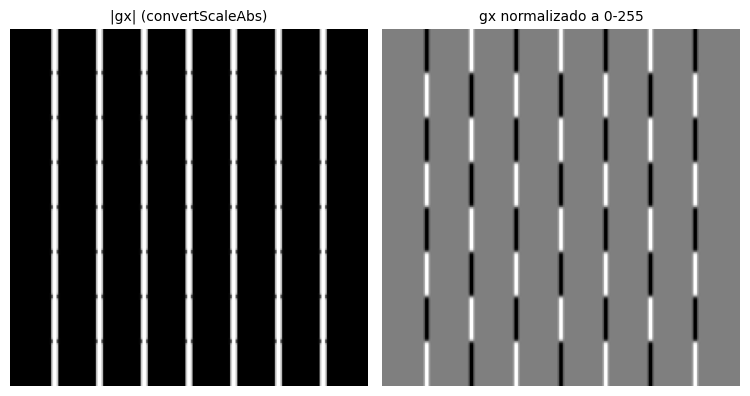

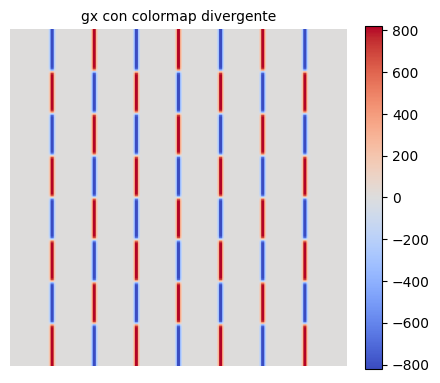

In [6]:
abs_vis = cv2.convertScaleAbs(g_float)
norm_vis = cv2.normalize(g_float, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

mostrar([abs_vis, norm_vis], ["|gx| (convertScaleAbs)", "gx normalizado a 0-255"],
        escala=3.8)
mostrar_signo(g_float, "gx con colormap divergente", escala=4.5)

## 4. Derivadas en una imagen discreta

Un borde es un cambio brusco de intensidad, así que detectarlo es **derivar**.
En una señal discreta la derivada se aproxima con diferencias finitas:

| Aproximación | Fórmula | Kernel |
|---|---|---|
| Hacia adelante | $f(n+1) - f(n)$ | `[-1, 1]` |
| Hacia atrás | $f(n) - f(n-1)$ | `[1, -1]` |
| **Centrada** | $\dfrac{f(n+1) - f(n-1)}{2}$ | `[-1, 0, 1]` |

Se prefiere la **centrada**: las otras dos estiman la derivada en un punto
desplazado medio píxel, y ese medio píxel se acumula al encadenar operaciones.
La centrada está bien centrada, a costa de no ver el píxel del medio.

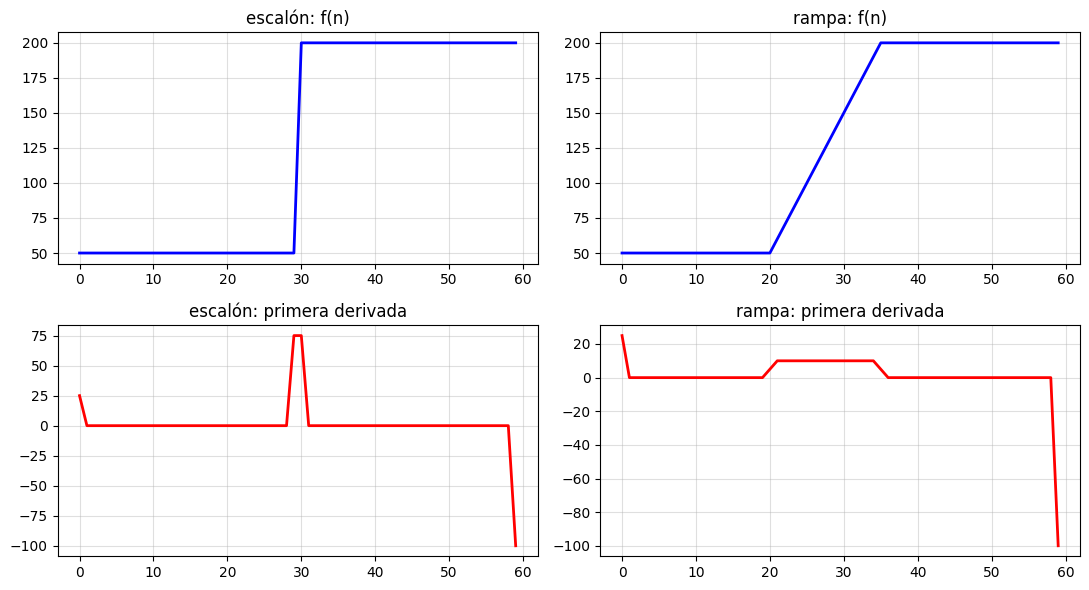

In [7]:
# Señales sintéticas 1-D: escalón y rampa
n = np.arange(60)
escalon = np.where(n < 30, 50.0, 200.0)
rampa = np.clip(50 + (n - 20) * 10.0, 50, 200)

def derivada_centrada(s):
    return np.convolve(s, [1, 0, -1], mode="same") / 2   # kernel girado = convolución

fig, axs = plt.subplots(2, 2, figsize=(11, 6))
for col, (s, nombre) in enumerate([(escalon, "escalón"), (rampa, "rampa")]):
    axs[0, col].plot(s, "b-", lw=2); axs[0, col].set_title(f"{nombre}: f(n)")
    axs[1, col].plot(derivada_centrada(s), "r-", lw=2)
    axs[1, col].set_title(f"{nombre}: primera derivada")
    for ax in axs[:, col]:
        ax.grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

flancos abruptos (escalones) máximo   75.0 | mínimo  -75.0 |  4 muestras no nulas
flancos graduales (rampas)   máximo   15.0 | mínimo  -15.0 | 22 muestras no nulas


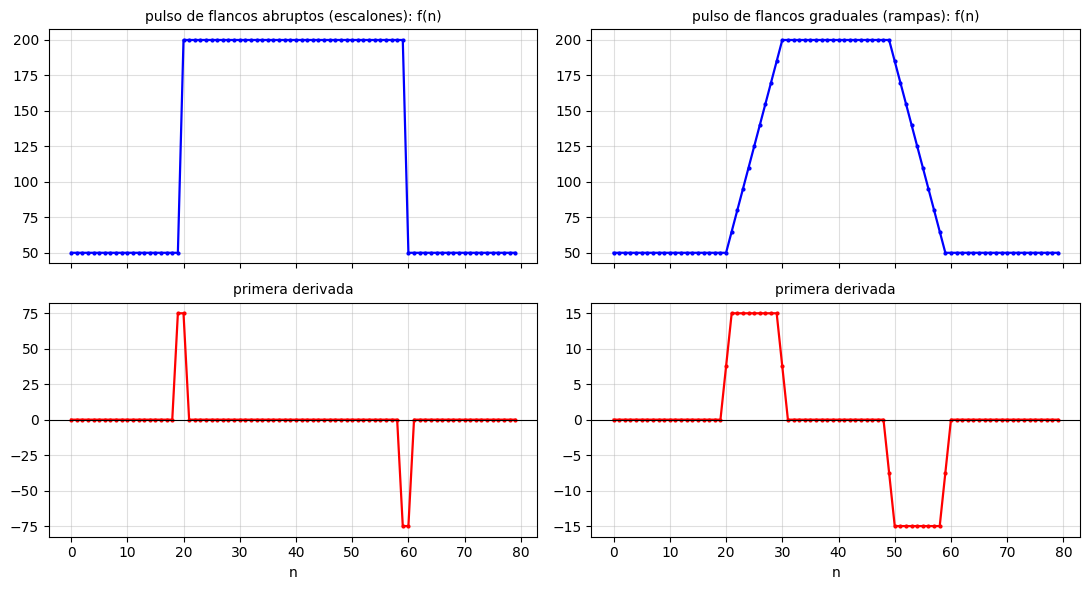

In [8]:
# Señales sintéticas 1-D: dos pulsos con el mismo alto y el mismo ancho,
# pero con flancos distintos
n = np.arange(80)

# Pulso de flancos abruptos: dos escalones opuestos
pulso_escalon = np.where((n >= 20) & (n < 60), 200.0, 50.0)

# Pulso de flancos graduales: dos rampas opuestas (trapecio)
ancho_rampa = 10
pulso_rampa = np.minimum(
    np.clip(50 + (n - 20) * (150 / ancho_rampa), 50, 200),   # flanco de subida
    np.clip(50 + (59 - n) * (150 / ancho_rampa), 50, 200),   # flanco de bajada
)


def derivada_centrada(s):
    # Se replican los extremos antes de convolucionar: con el relleno de ceros
    # de mode="same" aparecerían flancos falsos en n=0 y n=79, que no existen
    # en la señal. Es el mismo problema que borderType en 2-D.
    s_ext = np.pad(s, 1, mode="edge")
    return np.convolve(s_ext, [1, 0, -1], mode="valid") / 2   # kernel girado = convolución


fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for col, (s, nombre) in enumerate([(pulso_escalon, "flancos abruptos (escalones)"),
                                   (pulso_rampa, "flancos graduales (rampas)")]):
    d = derivada_centrada(s)
    axs[0, col].plot(n, s, "b.-", lw=1.6, ms=4)
    axs[0, col].set_title(f"pulso de {nombre}: f(n)", fontsize=10)
    axs[1, col].plot(n, d, "r.-", lw=1.6, ms=4)
    axs[1, col].axhline(0, color="k", lw=0.8)
    axs[1, col].set_title("primera derivada", fontsize=10)
    axs[1, col].set_xlabel("n")
    for ax in axs[:, col]:
        ax.grid(True, alpha=0.4)

    print(f"{nombre:28s} máximo {d.max():6.1f} | mínimo {d.min():6.1f} | "
          f"{np.count_nonzero(np.abs(d) > 1e-9):2d} muestras no nulas")

plt.tight_layout(); plt.show()

### Análisis

- En el **escalón** la derivada es un impulso: un solo valor grande justo en la
  transición. Ese es el caso ideal de un borde.
- En la **rampa** la derivada es una meseta: responde en toda la extensión de la
  transición, no en un punto. Los bordes reales son rampas, no escalones —
  el desenfoque óptico y el propio muestreo los ensanchan — así que un
  detector de gradiente produce bordes **gruesos**. Adelgazarlos requiere un
  paso extra (supresión de no-máximos), que es parte de Canny.

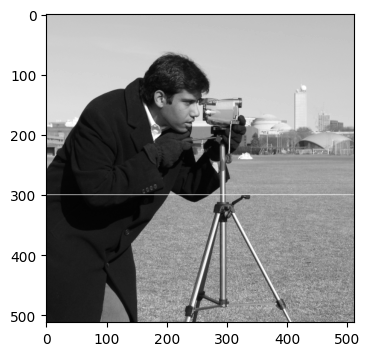

In [9]:
# Mostrar la iamgen camara y subrayar la fila 200, que se usará para el perfil
img = data.camera()
fila = 300
img[fila, :] = 255  # subrayar la fila 200

plt.imshow(img, cmap="gray", vmin=0, vmax=255)

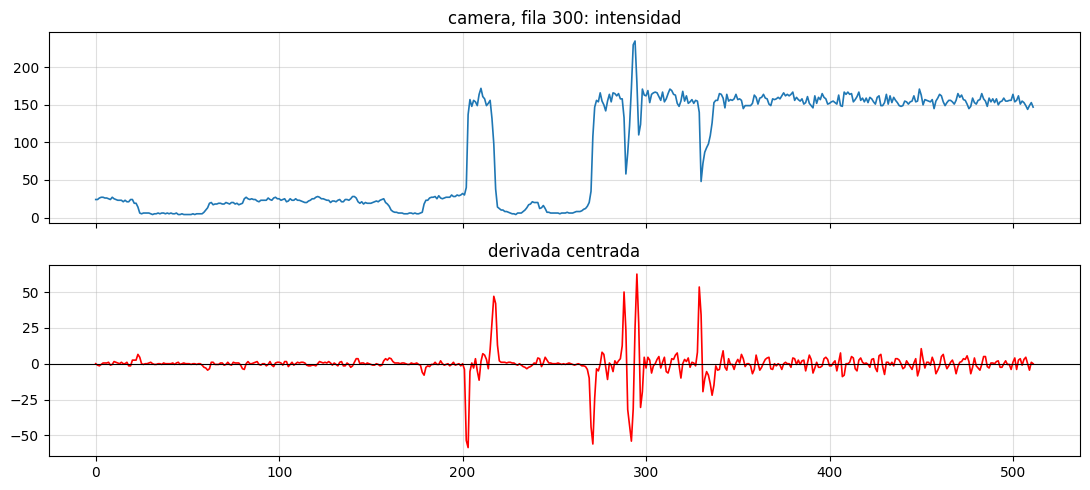

Máximo positivo: 62.5 en la columna 295
Máximo negativo: -58.5 en la columna 203


In [10]:
# Lo mismo sobre una fila real de la imagen
img = data.camera()
perfil = img[fila].astype(np.float64)
derivada = cv2.filter2D(perfil.reshape(1, -1), cv2.CV_64F,
                        np.array([[1, 0, -1]], np.float32) / 2).ravel()

fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axs[0].plot(perfil, lw=1.2); axs[0].set_title(f"camera, fila {fila}: intensidad")
axs[1].plot(derivada, "r-", lw=1.2); axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_title("derivada centrada")
for ax in axs: ax.grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

print("Máximo positivo:", derivada.max().round(1),
      "en la columna", int(np.argmax(derivada)))
print("Máximo negativo:", derivada.min().round(1),
      "en la columna", int(np.argmin(derivada)))

### Correlación y convolución: aquí sí importa el signo

El kernel `[-1, 0, 1]` es **antisimétrico**: al girarlo 180° cambia de signo,
$h[-i] = -h[i]$. Como `cv2.filter2D` calcula correlación y no convolución, el
resultado sale con el signo cambiado respecto de la definición de convolución.

La magnitud no cambia, pero la polaridad sí: lo que la correlación marca como
transición positiva, la convolución lo marca como negativa. Si tu código usa el
signo para decidir la dirección de un borde, la elección importa.

In [11]:
d = np.array([[-1, 0, 1]], np.float32)

correlacion = cv2.filter2D(img, cv2.CV_64F, d)
convolucion = cv2.filter2D(img, cv2.CV_64F, cv2.flip(d, -1))

print("¿convolución == -correlación?", np.allclose(convolucion, -correlacion))
print("¿|convolución| == |correlación|?",
      np.allclose(np.abs(convolucion), np.abs(correlacion)))

¿convolución == -correlación? True
¿|convolución| == |correlación|? True


## 5. Operadores de gradiente

En 2-D la derivada se convierte en el **vector gradiente**:

$$\nabla f = \left[\frac{\partial f}{\partial x},\; \frac{\partial f}{\partial y}\right]
\qquad
|\nabla f| = \sqrt{g_x^{2} + g_y^{2}}
\qquad
\theta = \arctan\!\left(\frac{g_y}{g_x}\right)$$

Hacen falta **dos** kernels, uno por dirección. Los cuatro operadores clásicos
no son una lista arbitraria: son una genealogía.

| Operador | Tamaño | Idea |
|---|---|---|
| **Roberts** (1963) | 2×2 | diferencias en diagonal; mínimo costo, sin centro definido |
| **Prewitt** (1970) | 3×3 | derivada en una dirección + promedio **uniforme** en la otra |
| **Sobel** (1968) | 3×3 | igual, pero el promedio es **ponderado** `[1,2,1]` |
| **Scharr** | 3×3 | coeficientes optimizados para mejor isotropía |

La diferencia entre Prewitt y Sobel es exactamente el vector de suavizado:
`[1,1,1]` contra `[1,2,1]`.

In [12]:
operadores = {
    "Roberts": (np.array([[1, 0], [0, -1]], np.float32),
                np.array([[0, 1], [-1, 0]], np.float32)),
    "Prewitt": (np.array([[-1, 0, 1]] * 3, np.float32),
                np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float32)),
    "Sobel":   (np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
                np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32)),
    "Scharr":  (np.array([[-3, 0, 3], [-10, 0, 10], [-3, 0, 3]], np.float32),
                np.array([[-3, -10, -3], [0, 0, 0], [3, 10, 3]], np.float32)),
}

for nombre, (kx, ky) in operadores.items():
    print(f"{nombre}  (suma kx = {kx.sum():.0f})")
    print(kx.astype(int), "\n")

Roberts  (suma kx = 0)
[[ 1  0]
 [ 0 -1]] 

Prewitt  (suma kx = 0)
[[-1  0  1]
 [-1  0  1]
 [-1  0  1]] 

Sobel  (suma kx = 0)
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]] 

Scharr  (suma kx = 0)
[[ -3   0   3]
 [-10   0  10]
 [ -3   0   3]] 



### La separabilidad de Sobel explica su diseño

El kernel de Sobel en $x$ es el producto externo de dos vectores 1-D:

$$\begin{bmatrix}1\\2\\1\end{bmatrix} \cdot \begin{bmatrix}-1 & 0 & 1\end{bmatrix}
= \begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}$$

Es decir: **suaviza con `[1,2,1]` en vertical y deriva con `[-1,0,1]` en
horizontal**. No es un operador de derivada a secas, es una derivada regularizada.

In [13]:
suavizado = np.array([[1], [2], [1]], np.float32)
derivada_1d = np.array([[-1, 0, 1]], np.float32)

print("Producto externo:\n", (suavizado @ derivada_1d).astype(int))
print("\n¿Coincide con el Sobel en x?",
      np.array_equal(suavizado @ derivada_1d, operadores["Sobel"][0]))

Producto externo:
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]

¿Coincide con el Sobel en x? True


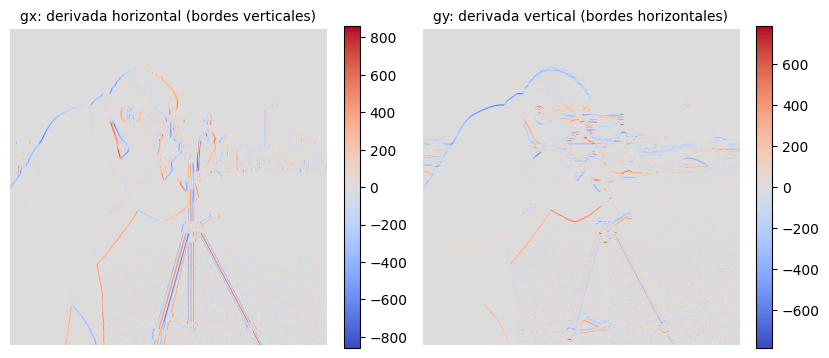

In [14]:
# Aplicación de los cuatro operadores: componentes gx y gy
img = data.camera()
gx_sobel = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
gy_sobel = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

mostrar_signo([gx_sobel, gy_sobel],
              ["gx: derivada horizontal (bordes verticales)",
               "gy: derivada vertical (bordes horizontales)"],
              escala=4.2)

Roberts  rango de magnitud: 0 a   263.8
Prewitt  rango de magnitud: 0 a   644.3
Sobel    rango de magnitud: 0 a   930.1
Scharr   rango de magnitud: 0 a  4020.9


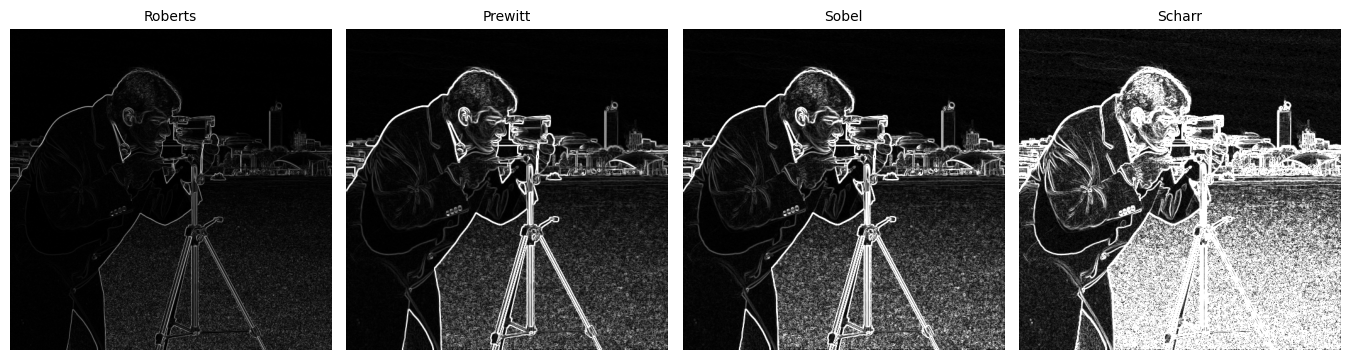

In [15]:
# Comparación de los cuatro operadores usando la magnitud
img = data.camera()
#img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

def magnitud(imagen, kx, ky):
    gx = cv2.filter2D(imagen, cv2.CV_64F, kx)
    gy = cv2.filter2D(imagen, cv2.CV_64F, ky)
    return cv2.magnitude(gx, gy)

mags = {n: magnitud(img, kx, ky) for n, (kx, ky) in operadores.items()}

for n, m in mags.items():
    print(f"{n:8s} rango de magnitud: 0 a {m.max():7.1f}")

mostrar([cv2.convertScaleAbs(m) for m in mags.values()],
        list(mags.keys()), cols=4, escala=3.4)

## 6. Magnitud, orientación y umbralización

### Tres formas de combinar $g_x$ y $g_y$

| Forma | Costo | Comentario |
|---|---|---|
| $\sqrt{g_x^2+g_y^2}$ (`cv2.magnitude`) | alto | la correcta, isótropa |
| $\|g_x\| + \|g_y\|$ | bajo | aproximación clásica, sobreestima en diagonal |
| `addWeighted(\|g_x\|, 0.5, \|g_y\|, 0.5)` | bajo | promedio, no magnitud; solo para visualizar |

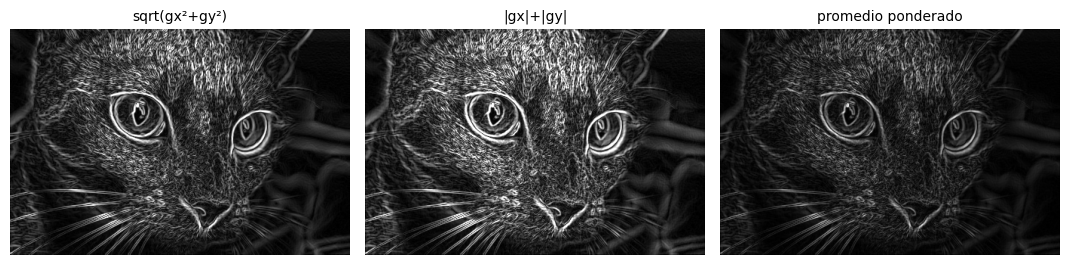

In [16]:
img = data.chelsea()
img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

mag_exacta = cv2.magnitude(gx, gy)
mag_l1 = np.abs(gx) + np.abs(gy)
mag_prom = cv2.addWeighted(np.abs(gx), 0.5, np.abs(gy), 0.5, 0)

mostrar([cv2.convertScaleAbs(m) for m in (mag_exacta, mag_l1, mag_prom)],
        ["sqrt(gx²+gy²)", "|gx|+|gy|", "promedio ponderado"], escala=3.6)

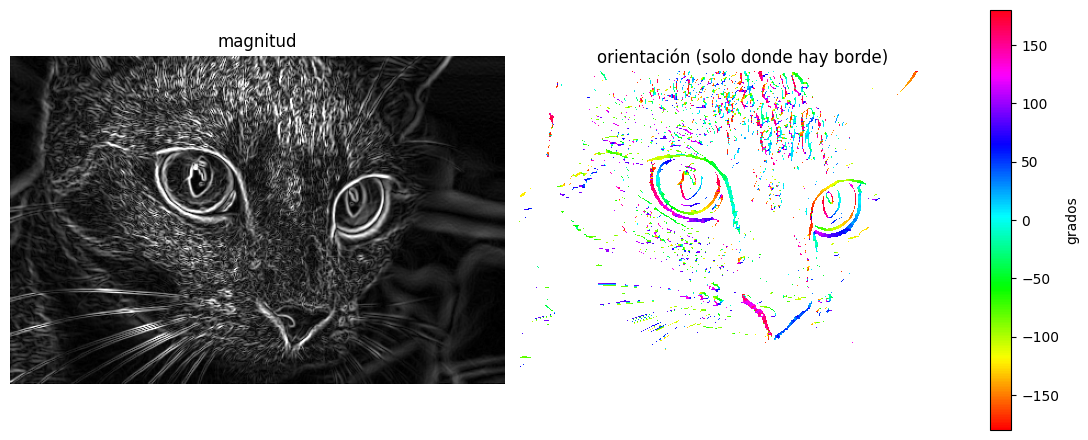

In [17]:
# Orientación del gradiente
angulo = np.degrees(np.arctan2(gy, gx))     # -180 a 180

mag_norm = cv2.normalize(mag_exacta, None, 0, 1, cv2.NORM_MINMAX)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
axs[0].imshow(cv2.convertScaleAbs(mag_exacta), cmap="gray")
axs[0].set_title("magnitud"); axs[0].axis("off")

# La orientación solo tiene sentido donde hay borde: se enmascara
ang_vis = np.where(mag_norm > 0.15, angulo, np.nan)
im = axs[1].imshow(ang_vis, cmap="hsv", vmin=-180, vmax=180)
axs[1].set_title("orientación (solo donde hay borde)"); axs[1].axis("off")
fig.colorbar(im, ax=axs[1], fraction=0.046, label="grados")
plt.tight_layout(); plt.show()

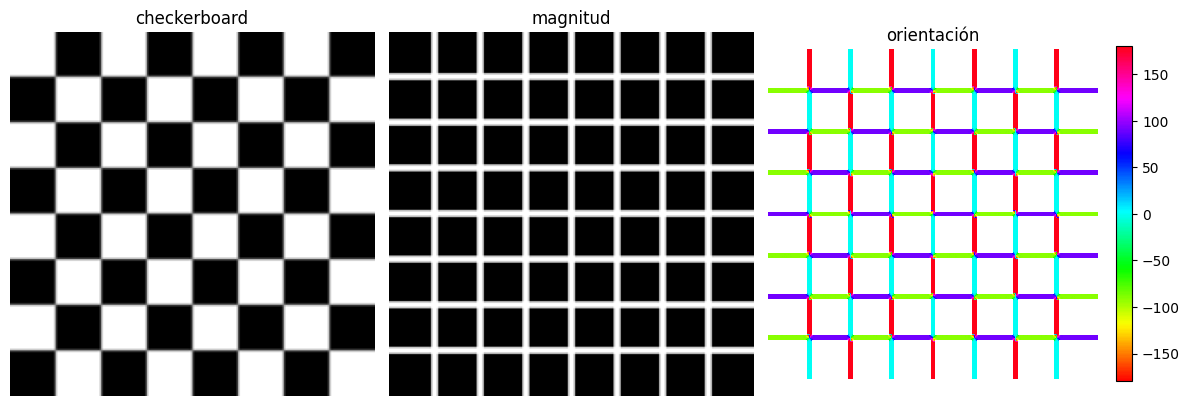

Orientaciones dominantes (grados):
    -180° :   0.9%
    -135° :   0.9%
     -90° :  24.1%
     -45° :   0.9%
       0° :  24.1%
      45° :   0.9%
      90° :  24.1%
     135° :   0.9%
     180° :  23.2%


In [18]:
# La orientación se lee mejor en una imagen con geometría simple
gx_t = cv2.Sobel(tablero, cv2.CV_64F, 1, 0, ksize=3)
gy_t = cv2.Sobel(tablero, cv2.CV_64F, 0, 1, ksize=3)
mag_t = cv2.magnitude(gx_t, gy_t)
ang_t = np.degrees(np.arctan2(gy_t, gx_t))

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(tablero, cmap="gray"); axs[0].set_title("checkerboard")
axs[1].imshow(cv2.convertScaleAbs(mag_t), cmap="gray"); axs[1].set_title("magnitud")
im = axs[2].imshow(np.where(mag_t > 0.15 * mag_t.max(), ang_t, np.nan),
                   cmap="hsv", vmin=-180, vmax=180)
axs[2].set_title("orientación")
for ax in axs: ax.axis("off")
fig.colorbar(im, ax=axs[2], fraction=0.046)
plt.tight_layout(); plt.show()

print("Orientaciones dominantes (grados):")
sel = mag_t > 0.5 * mag_t.max()
valores, cuentas = np.unique(np.round(ang_t[sel] / 45) * 45, return_counts=True)
for v, c in zip(valores, cuentas):
    print(f"  {v:6.0f}° : {100*c/cuentas.sum():5.1f}%")

### Umbralización: de mapa de magnitud a mapa binario

Un mapa de bordes binario requiere elegir un umbral, y esa elección es
**arbitraria**: no hay un valor correcto. Usar percentiles en vez de valores
absolutos al menos hace la elección comparable entre imágenes.

percentil 80: umbral =     91, 20.0% de píxeles marcados
percentil 90: umbral =    176, 10.0% de píxeles marcados
percentil 95: umbral =    272,  5.0% de píxeles marcados
percentil 98: umbral =    408,  2.0% de píxeles marcados


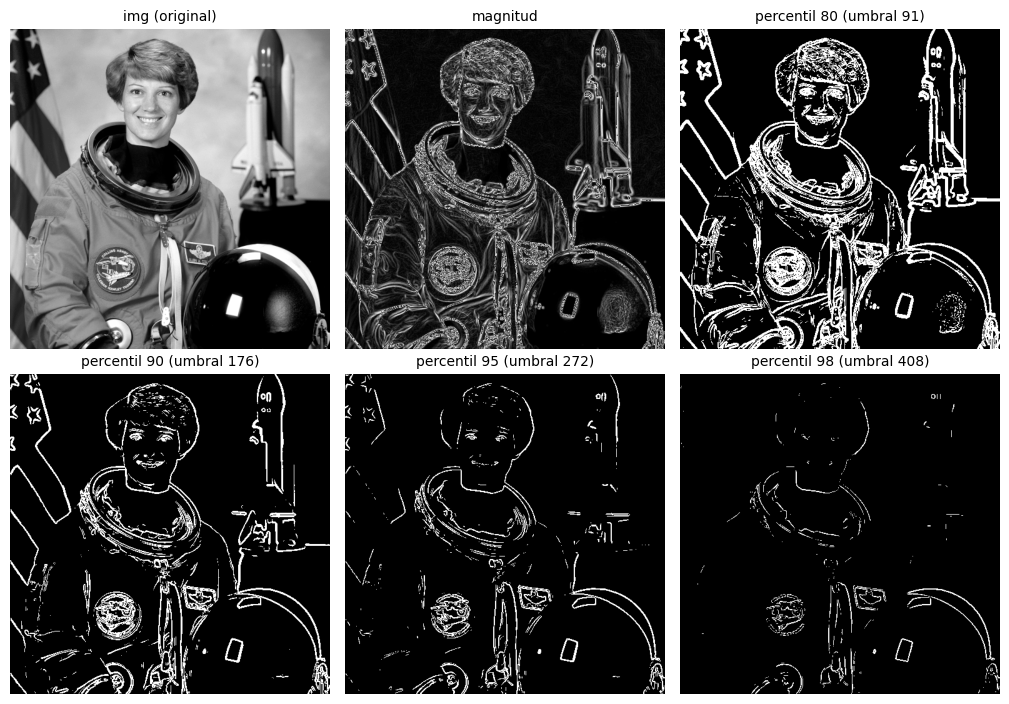

In [19]:
img = data.astronaut()
img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
gx_m = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
gy_m = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
mag_m = cv2.magnitude(gx_m, gy_m)

binarios, titulos = [img], ["img (original)"]
binarios.append(mag_m.astype(np.uint8))
titulos.append("magnitud")
for p in [80, 90, 95, 98]:
    u = np.percentile(mag_m, p)
    binarios.append(((mag_m > u) * 255).astype(np.uint8))
    titulos.append(f"percentil {p} (umbral {u:.0f})")
    print(f"percentil {p}: umbral = {u:6.0f}, {100*(mag_m>u).mean():4.1f}% de píxeles marcados")


mostrar(binarios, titulos, cols=3, escala=3.4)

### Análisis

El compromiso se ve de forma muy directa:

- Con el **percentil 80** aparecen los contornos completos de todas las monedas,
  pero también mucha respuesta del fondo texturado y del ruido: bordes reales
  con falsos positivos.
- Con el **percentil 98** el fondo queda limpio, pero los contornos se
  **fragmentan**: las monedas de la parte superior, donde el contraste con el
  fondo es menor, pierden trozos de borde.

Ningún umbral único resuelve las dos cosas, porque el contraste no es uniforme
en la imagen. Ese es exactamente el problema que ataca el **doble umbral con
histéresis** de Canny: un umbral alto para decidir qué es borde con seguridad y
uno bajo para prolongar los contornos ya iniciados. Lo vemos en la clase
siguiente.

## 7. Realce por enmascaramiento (*unsharp masking*)

Hasta aquí el pasaaltos se usó para **ver** los bordes. También sirve para
**mejorar** la imagen: si el detalle es lo que el suavizado quita, sumárselo de
vuelta a la original la hace más nítida.

$$\text{detalle} = f - f_{\text{suavizada}}
\qquad
f_{\text{realzada}} = f + k \cdot \text{detalle}$$

Con $k=1$ es *unsharp masking*; con $k>1$, *highboost*. El nombre despista: se
llama "máscara de desenfoque" porque el método venía de la fotografía química,
donde se usaba un negativo desenfocado como máscara.

Nota: el kernel de realce `[[0,-1,0],[-1,5,-1],[0,-1,0]]` que aparece en los
libros es otra forma de lo mismo, construida con el laplaciano. Lo veremos en
la clase siguiente.

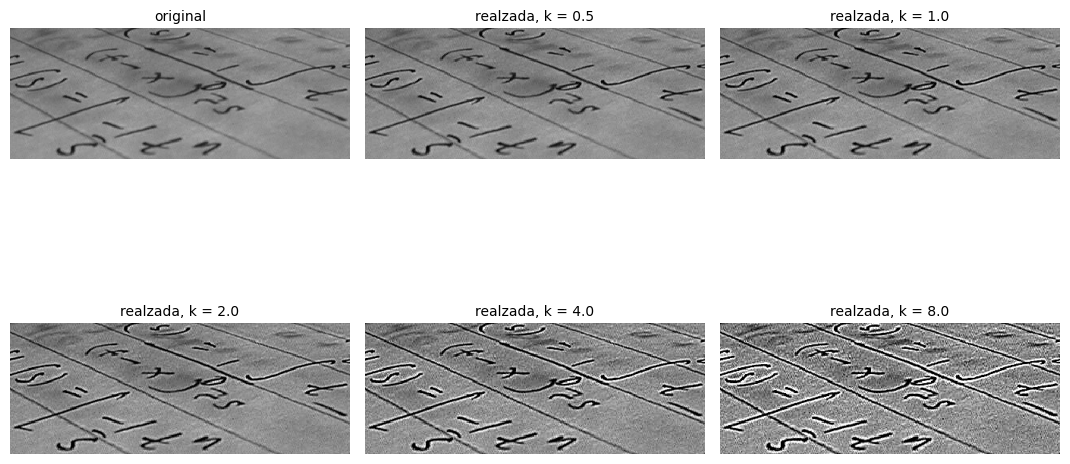

In [20]:
texto = data.text()          # imagen con detalle fino, buen caso para realce

def realzar(imagen, k=1.0, ksize=(9, 9), sigma=0):
    f = imagen.astype(np.float64)
    suave = cv2.GaussianBlur(f, ksize, sigma)
    detalle = f - suave
    return np.clip(f + k * detalle, 0, 255).astype(np.uint8), detalle


salidas, titulos = [texto], ["original"]
for k in [0.5, 1.0, 2.0, 4.0, 8.0]:
    r, _ = realzar(texto, k)
    salidas.append(r)
    titulos.append(f"realzada, k = {k}")

mostrar(salidas, titulos, cols=3, escala=3.6)

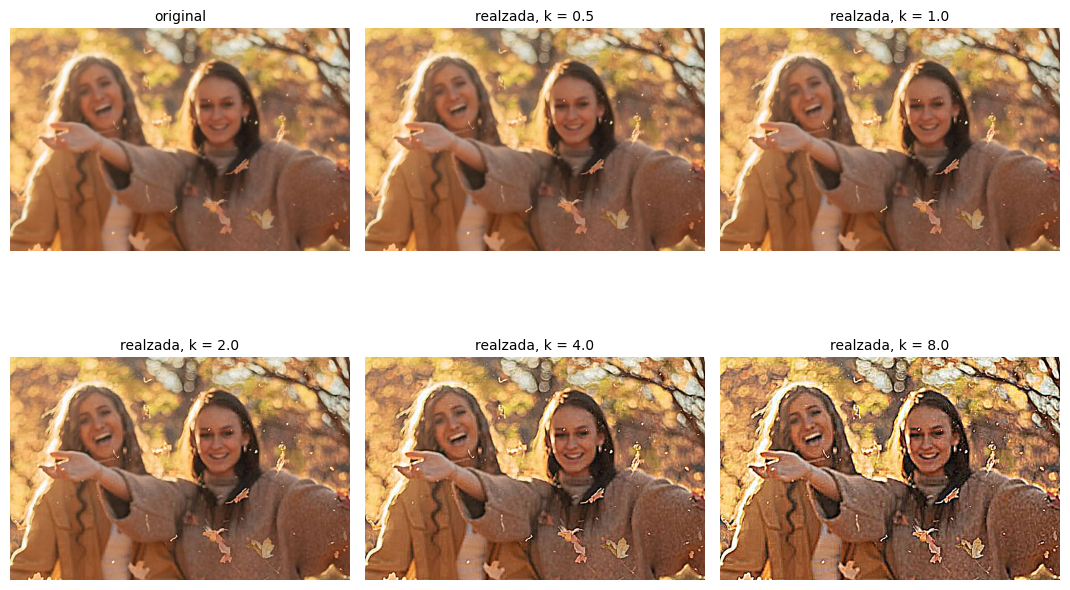

In [21]:
img = cv2.imread("faces.jpg")
salidas, titulos = [img], ["original"]
for k in [0.5, 1.0, 2.0, 4.0, 8.0]:
    r, _ = realzar(img, k)
    salidas.append(r)
    titulos.append(f"realzada, k = {k}")

mostrar(salidas, titulos, cols=3, escala=3.6)

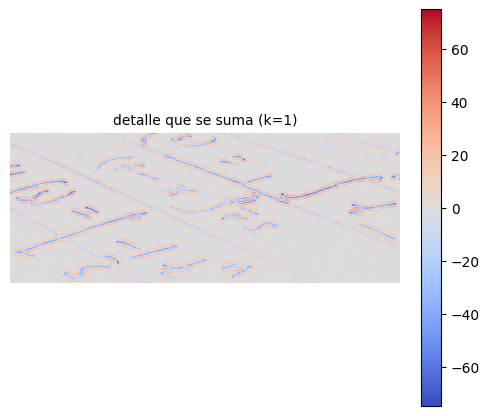

k = 0.5:   0.2% de píxeles en 0,   0.0% en 255
k = 1.0:   0.9% de píxeles en 0,   0.0% en 255
k = 2.0:   2.7% de píxeles en 0,   0.0% en 255
k = 4.0:   4.8% de píxeles en 0,   0.8% en 255


In [22]:
# Qué se está sumando exactamente
_, detalle_txt = realzar(texto, 1.0)
mostrar_signo(detalle_txt, "detalle que se suma (k=1)", escala=5.0)

for k in [0.5, 1.0, 2.0, 4.0]:
    r, _ = realzar(texto, k)
    print(f"k = {k}: {100*(r==0).mean():5.1f}% de píxeles en 0, "
          f"{100*(r==255).mean():5.1f}% en 255")

### Análisis

El realce no agrega información: **redistribuye contraste local**. Se nota en
tres síntomas conforme sube `k`:

- Aparecen **halos** a los lados de cada trazo: un borde de un tono más claro
  del lado claro y más oscuro del lado oscuro. Es el detalle sumado, y es el
  artefacto característico del método.
- Crece el porcentaje de píxeles **saturados** en 0 y 255. Ese recorte sí
  destruye información de forma irreversible.
- El **ruido también se realza**, porque el ruido es alta frecuencia igual que
  el detalle. En una imagen ruidosa, `k` alto empeora el resultado.

El tamaño del gaussiano importa tanto como `k`: define **a qué escala** se
realza. Un sigma pequeño acentúa la textura fina; uno grande acentúa las
estructuras grandes y produce halos anchos y visibles.

## 8. Higiene experimental

### 8.1 Suavizar antes de derivar

Derivar **amplifica el ruido**: el ruido es alta frecuencia, y un pasaaltos es
precisamente lo que la deja pasar. Por eso todo detector de bordes serio
empieza con un suavizado gaussiano.

Para medirlo se usa una región plana de la imagen, donde no hay bordes reales:
toda respuesta ahí es espuria.

limpia                     |grad| medio en zona plana =   15.3
ruidosa, sin suavizar      |grad| medio en zona plana =   92.2
ruidosa + gaussiano 5x5    |grad| medio en zona plana =   33.9


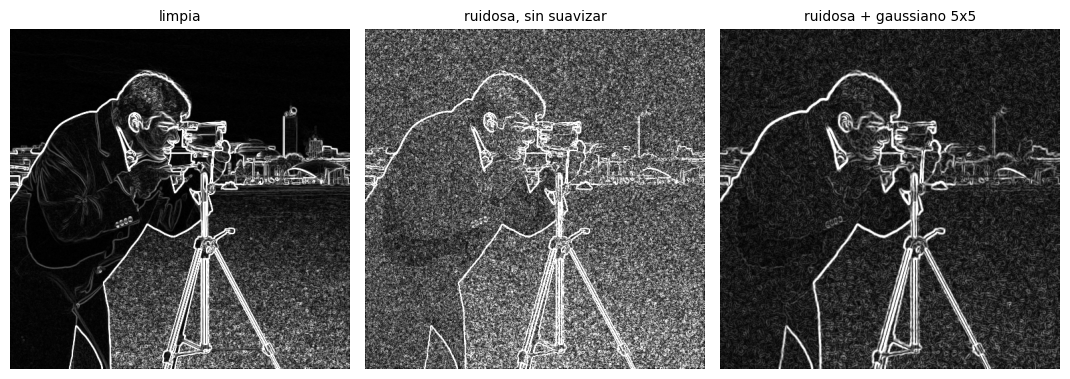

In [23]:
img = data.camera()
rng = np.random.default_rng(0)
ruidosa = np.clip(img + rng.normal(0, 20, img.shape), 0, 255).astype(np.uint8)

cielo = (slice(0, 120), slice(0, 250))    # zona sin bordes

def magnitud_sobel(imagen, presuavizar=False, k=5):
    x = cv2.GaussianBlur(imagen, (k, k), 0) if presuavizar else imagen
    return cv2.magnitude(cv2.Sobel(x, cv2.CV_64F, 1, 0, ksize=3),
                         cv2.Sobel(x, cv2.CV_64F, 0, 1, ksize=3))

casos = [("limpia", magnitud_sobel(img)),
         ("ruidosa, sin suavizar", magnitud_sobel(ruidosa)),
         ("ruidosa + gaussiano 5x5", magnitud_sobel(ruidosa, True))]

for nombre, m in casos:
    print(f"{nombre:26s} |grad| medio en zona plana = {m[cielo].mean():6.1f}")

mostrar([cv2.convertScaleAbs(m) for _, m in casos],
        [n for n, _ in casos], escala=3.6)

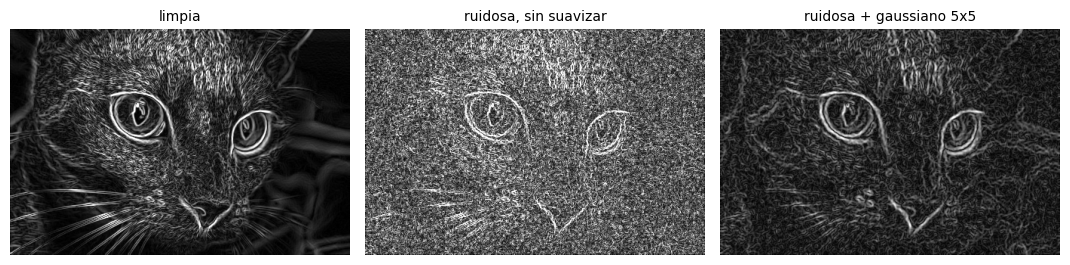

In [24]:
img = data.chelsea()
img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
rng = np.random.default_rng(0)
ruidosa = np.clip(img + rng.normal(0, 20, img.shape), 0, 255).astype(np.uint8)

def magnitud_sobel(imagen, presuavizar=False, k=5):
    x = cv2.GaussianBlur(imagen, (k, k), 0) if presuavizar else imagen
    return cv2.magnitude(cv2.Sobel(x, cv2.CV_64F, 1, 0, ksize=3),
                         cv2.Sobel(x, cv2.CV_64F, 0, 1, ksize=3))

casos = [("limpia", magnitud_sobel(img)),
         ("ruidosa, sin suavizar", magnitud_sobel(ruidosa)),
         ("ruidosa + gaussiano 5x5", magnitud_sobel(ruidosa, True))]


mostrar([cv2.convertScaleAbs(m) for _, m in casos],
        [n for n, _ in casos], escala=3.6)